# 07 Active satellites and the operator offset ratio (question 3)

Active satellites join the analysis table here (`is_active = 1`), only for the offset ratio, never
pooled with the passive objects.

1. Cohort: `python -m src.active_cohort` picks 25 Starlink + 25 other payloads (400-800 km, ecc < 0.01,
   coverage on 8 of 9 sample dates), downloads their TLEs and builds the decay intervals.
2. Objects: `objects.build_objects` on the cohort + actives (SATCAT, DISCOSweb, maneuver search).
3. Physics: `python -m src.build_table` runs the same MSIS 2.1 / NRLMSISE-00 drivers for the actives,
   with a catalog drag sensitivity (2.2 x A/m, scaled by the fitted / catalog ratio of rocket bodies at
   the same altitude), and flags rows where a satellite stops station keeping (`free_drag`).
4. Offset ratio: `python -m src.causal_run` (results in `results/causal`).

Question 3 is effectively a Starlink study: 25 of the 26 active objects are Starlink, and the one other
is a dead satellite (below).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import build_table as bt
from src import offset_ratio as orr
from src import plots
from src.schema import load_table, main_sample
from src.storms import load_storms

PROCESSED = ROOT / "data" / "processed"
RESULTS = ROOT / "results"
table = load_table()
storms = load_storms()
objects = pd.read_parquet(PROCESSED / "objects.parquet")
manifest = pd.read_parquet(PROCESSED / "active_cohort_manifest.parquet")
activity = pd.read_parquet(PROCESSED / "active_activity.parquet")
drag = pd.read_parquet(PROCESSED / "active_drag.parquet")
active = table[table["is_active"] == 1]
passive = table[table["is_active"] == 0]
print(f"table: {len(table):,} rows, {table['norad_id'].nunique()} objects; "
      f"active: {len(active):,} rows, {active['norad_id'].nunique()} objects")

table: 219,480 rows, 291 objects; active: 19,900 rows, 26 objects


## 1. Cohort and activity

In [2]:
act = activity.merge(manifest[["norad_id", "group"]], on="norad_id")
print(pd.crosstab(act["group"], act["is_active"].map({0: "passive", 1: "active"})))
print()
print(act.loc[act["is_active"] == 1].groupby("group")["object_name"].apply(list).to_string())

is_active  active  passive
group                     
other           1       24
starlink       25        0

group
other                                           [SURCAL 150B]
starlink    [STARLINK-2038, STARLINK-3275, STARLINK-3949, ...


All 25 Starlinks are active (Starlink name = low-thrust station keeping, `objects.classify_activity`).
Of the 25 other payloads (mostly old Cosmos / TIROS satellites: the selection ranks by coverage, then
NORAD ID) only SURCAL 150B, a 1967 calibration satellite, is called active, from 2 "maneuvers". It
decays by ~300 m/day all year and never climbs (plot below): the maneuvers are false alarms on a fast
decayer, and the free-drag flag removes all of its rows.

## 2. Drag sensitivity from the catalog

,object_name,alt_km,B_catalog,scale,n_bodies,B
norad_id,,,,,,
2909,SURCAL 150B,600.912,0.026,0.519,41,0.014
44714,STARLINK-1008,554.059,0.115,0.771,8,0.088
44716,STARLINK-1010,553.943,0.115,0.771,8,0.088
44717,STARLINK-1011,554.082,0.115,0.771,8,0.088
44718,STARLINK-1012,554.052,0.115,0.771,8,0.088
44719,STARLINK-1013,553.968,0.115,0.771,8,0.088
44721,STARLINK-1015,554.358,0.115,0.771,8,0.088
44723,STARLINK-1017,554.078,0.115,0.771,8,0.088
44724,STARLINK-1019,554.015,0.115,0.771,8,0.088


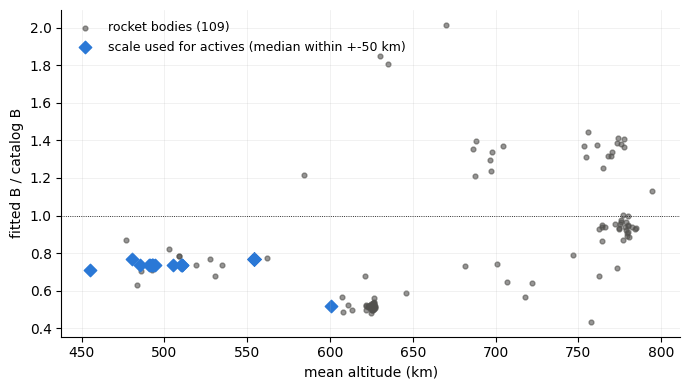

In [3]:
rows = passive[(passive["cohort_group"] == "main") & (passive["drag_source"] == "fit")]
bodies = rows.groupby("norad_id").agg(B=("drag_sensitivity", "first"), alt_km=("alt_km", "mean")).join(
    objects.set_index("norad_id")[["object_type", "drag_sensitivity_catalog"]])
bodies = bodies[(bodies["object_type"] == "rocket body") & (bodies["drag_sensitivity_catalog"] > 0)]
bodies["ratio"] = bodies["B"] / bodies["drag_sensitivity_catalog"]
plots.plot_catalog_scale(bodies, drag, out_path=RESULTS / "actives_drag_scale.png")
d = drag.join(objects.set_index("norad_id")["object_name"])
d[["object_name", "alt_km", "B_catalog", "scale", "n_bodies", "B"]].round(3)

B = 2.2 x A/m (DISCOSweb: Starlink v1.0 260 kg / 13.6 m^2, v1.5 305 kg, v2 mini 730 kg) times the
median fitted / catalog ratio of the rocket bodies within +-50 km (0.71-0.77 at 450-555 km, 5-11
bodies). A straight-line fit of the ratio in altitude was rejected: one stage type (39 bodies at
600-650 km, ratio ~0.5) drags it to ~0.5 at Starlink altitudes, far from the bodies actually there.
The ratio rests on few bodies (and fewer stage types), and a Starlink's drag area changes with its
attitude, which is exactly what "ducking" changes, so B is a fixed reference, not a fit.

## 3. Satellites that stop station keeping (`free_drag`)

objects with flagged rows: 17 of 26; fully excluded (>= 99% of rows): 5; rows flagged: 7,065 of 19,900


,object_name,free_drag,first_flag,flagged_days,flagged_share,kind
norad_id,,,,,,
2909,SURCAL 150B,1,2024-04-01 12:30:13.377893,382.42,1.00,lowering
44714,STARLINK-1008,0,NaT,0.00,0.00,None
44716,STARLINK-1010,1,2025-04-05 20:58:21.492749,21.72,0.06,lowering
44717,STARLINK-1011,0,NaT,0.00,0.00,None
44718,STARLINK-1012,0,NaT,0.00,0.00,None
44719,STARLINK-1013,1,2025-04-05 20:26:30.524358,21.01,0.06,lowering
44721,STARLINK-1015,1,2024-07-27 11:56:21.306919,62.58,0.16,drag
44723,STARLINK-1017,0,NaT,0.00,0.00,None
44724,STARLINK-1019,0,NaT,0.00,0.00,None


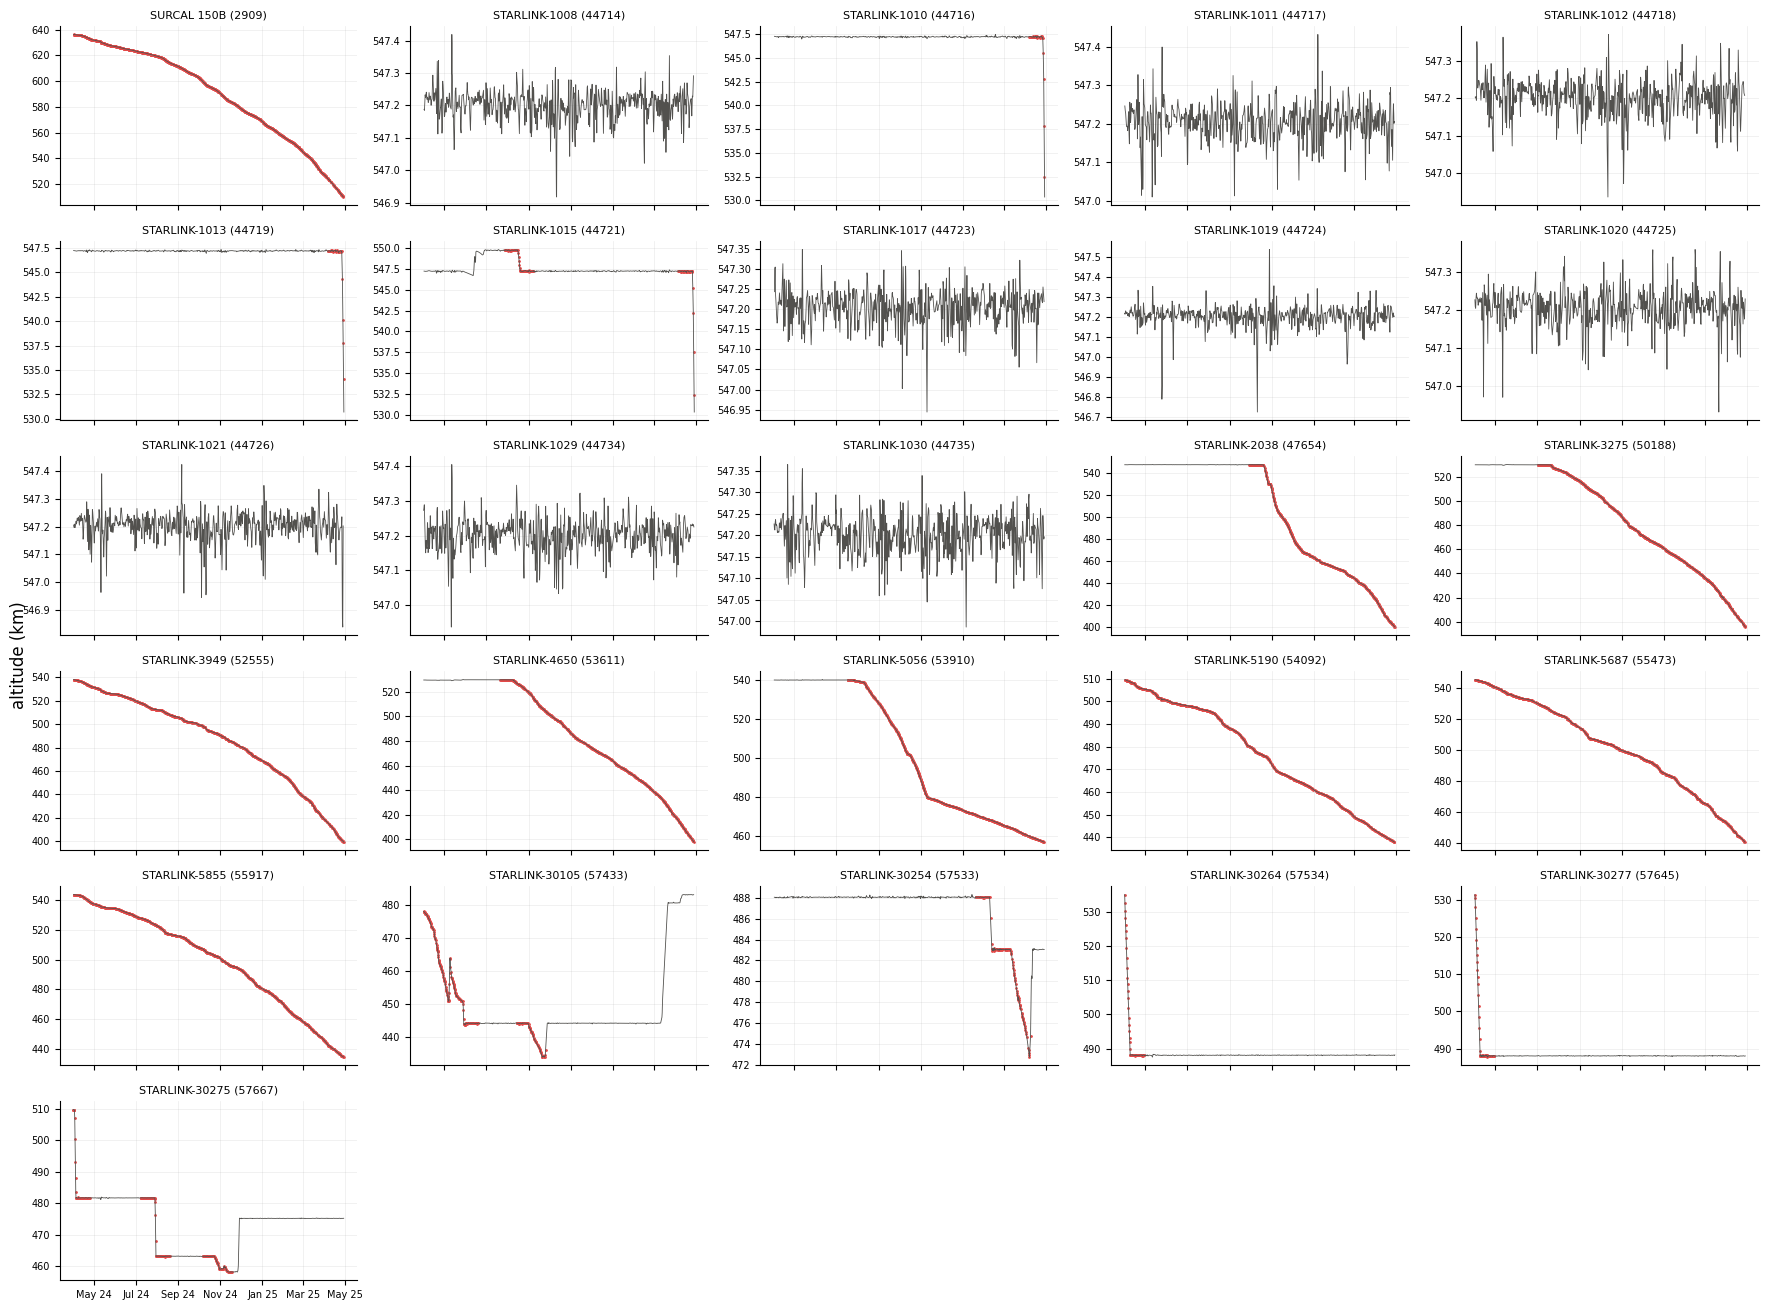

In [4]:
plots.plot_active_altitudes(active, out_path=RESULTS / "actives_free_drag.png")
flags = d[["object_name", "free_drag", "first_flag", "flagged_days", "flagged_share", "kind"]]
print(f"objects with flagged rows: {int(flags['free_drag'].sum())} of {len(flags)}; "
      f"fully excluded (>= 99% of rows): {int((flags['flagged_share'] >= 0.99).sum())}; "
      f"rows flagged: {int(active['free_drag'].sum()):,} of {len(active):,}")
flags.round(2)

Rule (`build_table.free_drag_flags`): over any 21-day window the satellite loses more than 1 km and at
least 10% of the free-drag loss predicted with its catalog B. Station-keeping Starlinks hold altitude
(|observed / predicted| < 0.15, < 0.5 km per 3 weeks); a storm costs a few hundred metres for a few days
and the operator climbs back, so it never triggers. Flags are per row: a satellite moved to a lower
shell keeps its station-keeping periods. Deorbiting Starlinks decay at only 0.2-0.5 of the catalog
free-drag rate (low-drag attitude), which is why the lower bound is 10%, not 50%.

## 4. Offset ratio on real data

In [5]:
summary = (RESULTS / "causal" / "summary.md").read_text()
print(summary[summary.index("## Offset ratio"):])

## Offset ratio (storm loss on Y_total)

**Not estimated: Fewer than 2 storms with matched pairs.**

- Storms with usable active satellites after the neighbouring-storm cut: 3 of 20.
- Nearest passive twin (standardised distance, caliper 0.5): median 1.11, smallest 1.03.
- Debris placebo over 20 random sets: ducking share mean -0.040, SD 0.158; offset ratio mean 0.096, SD 0.448.

| Storm | Onset | Usable actives | Usable passives | Nearest twin (median) | Matched |
|---|---|---|---|---|---|
| 5 | 2024-06-27 | 19 | 226 | 1.34 | 0 |
| 12 | 2024-11-08 | 16 | 236 | 1.11 | 0 |
| 13 | 2024-12-31 | 17 | 247 | 1.03 | 0 |



In [6]:
diag = pd.read_csv(RESULTS / "causal" / "offset_match_diagnostics.csv")
diag

,storm_id,main_onset,usable_actives,usable_passives,nearest_median,nearest_min,matched_actives
0,1,2024-04-19 00:00:00,0,0,NaN,NaN,0
1,2,2024-04-25 19:00:00,0,0,NaN,NaN,0
2,3,2024-05-02 09:00:00,0,0,NaN,NaN,0
3,4,2024-05-10 17:00:00,0,0,NaN,NaN,0
4,5,2024-06-27 17:00:00,19,226,1.339441,1.321724,0
5,6,2024-08-03 19:00:00,0,0,NaN,NaN,0
6,7,2024-08-11 19:00:00,0,0,NaN,NaN,0
7,8,2024-08-27 09:00:00,0,0,NaN,NaN,0
8,9,2024-09-12 04:00:00,0,0,NaN,NaN,0
9,10,2024-09-24 05:00:00,0,0,NaN,NaN,0


passive objects at 440-570 km and 38-58 deg: 0


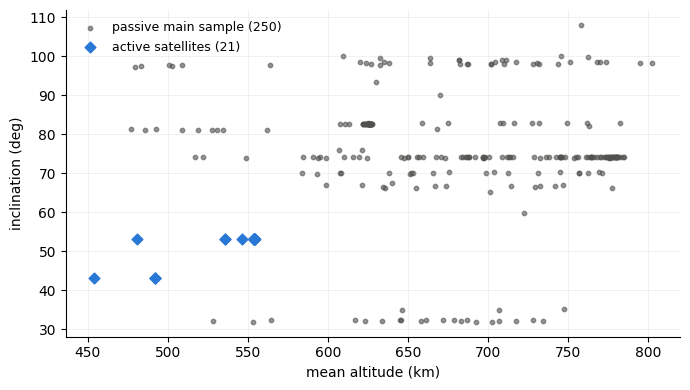

In [7]:
ms = main_sample(table).groupby("norad_id")[["alt_km", "inc_deg"]].mean()
ac = orr._clean_actives(table).groupby("norad_id")[["alt_km", "inc_deg"]].mean()
plots.plot_match_gap(ms, ac, out_path=RESULTS / "actives_match_gap.png")
near = ms[ms["alt_km"].between(440, 570) & ms["inc_deg"].between(38, 58)]
print(f"passive objects at 440-570 km and 38-58 deg: {len(near)}")

**The pre-set offset ratio cannot be estimated with this passive pool.** Two separate reasons:

- No twins: the passive cohort was chosen for the storm-effect question (spread over 400-800 km,
  mostly old rocket bodies at 74 / 82 deg). None sits near the usable Starlinks (43 and 53 deg at
  450-555 km). The nearest passive object is more than twice the caliper (0.5 SD) from every Starlink.
- Few clean storms: with pre (-10..-3 days), ducking and a 10-day recovery window that must be free of
  other storms, only 3 of the 20 storms are usable (Jun 27, Nov 8, Dec 31 2024). May and Oct 2024 drop
  out because neighbouring storms overlap their windows.

The debris placebo (passive vs passive) runs and is reported in the summary above.

### Exploratory only: what a looser caliper gives

Not a result. Widening the caliper to 1.5 SD (and a 5-day recovery window, which keeps 6 storms)
forces pairs; the balance shows the twins are not comparable and the intervals are useless.

In [8]:
import warnings
warnings.filterwarnings("ignore")
for caliper, rec in [(1.5, 10), (1.5, 5)]:
    s, pairs, smd = orr.offset_ratio(table, storms, outcome="Y_total", n_boot=499, caliper=caliper,
                                     recovery_days=rec)
    print(f"caliper {caliper}, recovery {rec} days: {s.attrs['n_storms']} storms, {s.attrs['n_actives']} actives, "
          f"{s.attrs['n_pairs']} pairs; SMD {smd.round(2).to_dict()}")
    print(s.round(2).to_string(), end="\n\n")

caliper 1.5, recovery 10 days: 3 storms, 18 actives, 45 pairs; SMD {'alt_km': -1.76, 'inc_deg': -1.37, 'log_drag': 0.04}
                 est  ci_lo   ci_hi     se
ducking_share   0.63  -1.61    5.40   1.27
recovery_share -5.33 -63.84  114.55  32.34
offset_ratio   -4.70 -65.45  119.95  33.61



caliper 1.5, recovery 5 days: 6 storms, 18 actives, 79 pairs; SMD {'alt_km': -1.73, 'inc_deg': -1.33, 'log_drag': 0.06}
                 est  ci_lo  ci_hi     se
ducking_share   0.72  -3.24   1.78   3.97
recovery_share -2.17 -36.32   1.94  48.09
offset_ratio   -1.45 -39.70   3.56  51.49



## 5. Conclusion and next step

- 26 actives in the table: 25 Starlink + SURCAL 150B (a false-positive active, fully flagged). 17
  objects have `free_drag` rows (7,065 of 19,900 rows); 5 are excluded completely (SURCAL 150B and 4
  Starlinks deorbiting all year), 4 more from the start of their deorbit; 9 Starlinks are never flagged.
- Q3 is a Starlink study.
- The offset ratio needs passive twins near the Starlink shells: debris and rocket bodies at
  450-560 km and 40-56 / 70 deg (task A), or a counterfactual that does not need twins (the active
  satellite's own physics prediction). The contamination rule also leaves only 3 storms; the 5-day
  recovery window keeps 6.